In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Reload and prepare data
df = pd.read_csv('master_dataset.csv')
df['account_open_date'] = pd.to_datetime(df['account_open_date'])
df['interaction_date'] = pd.to_datetime(df['interaction_date'])

# Current date (from dataset context)
current_date = pd.to_datetime('2026-07-11')

In [2]:
#Construct Churn Labels(Retention Analysis)

# Since we don't have explicit churn, we define churn based on recency of interaction
# A customer is "At Risk / Churned" if their last interaction is beyond a threshold

# Calculate recency for each customer
customer_recency = df.groupby('customer_id').agg({
    'interaction_date': ['max', 'min', 'count'],
    'age': 'first',
    'account_type': 'first',
    'location_tier': 'first',
    'platform_logged': lambda x: x.mode()[0],
    'service_ticket_raised': lambda x: (x == 'Yes').sum(),
    'nps_score': 'mean',
    'txn_count': 'sum',
    'txn_sum': 'sum',
    'txn_avg': 'mean',
    'txn_min': 'min',
    'txn_max': 'max'
}).reset_index()

# Flatten column names
customer_recency.columns = ['customer_id', 'last_interaction', 'first_interaction', 
                            'interaction_count', 'age', 'account_type', 'location_tier',
                            'primary_platform', 'ticket_count', 'avg_nps', 'total_txn_count',
                            'total_txn_sum', 'avg_txn_amount', 'min_txn', 'max_txn']

# Calculate recency (days since last interaction)
customer_recency['recency_days'] = (current_date - customer_recency['last_interaction']).dt.days

# Calculate tenure
customer_recency['tenure_days'] = (current_date - customer_recency['first_interaction']).dt.days
customer_recency['tenure_years'] = customer_recency['tenure_days'] / 365.25

# Calculate frequency metrics
customer_recency['txn_frequency'] = customer_recency['total_txn_count'] / (customer_recency['tenure_years'] + 0.01)
customer_recency['interaction_frequency'] = customer_recency['interaction_count'] / (customer_recency['tenure_years'] + 0.01)

# Define churn based on recency thresholds
# Using 90-day threshold (common in fintech for quarterly engagement)
customer_recency['churned_90d'] = (customer_recency['recency_days'] > 90).astype(int)

# Also create a more nuanced "At Risk" category
def churn_risk(row):
    if row['recency_days'] > 120:
        return 'Churned'
    elif row['recency_days'] > 60:
        return 'At Risk'
    else:
        return 'Active'

customer_recency['churn_risk'] = customer_recency.apply(churn_risk, axis=1)

# Create binary target for modeling
customer_recency['is_churned'] = (customer_recency['churn_risk'] == 'Churned').astype(int)

print("CHURN LABEL DISTRIBUTION")
print(customer_recency['churn_risk'].value_counts())
print(f"\nChurn Rate: {customer_recency['is_churned'].mean():.1%}")
print(f"\nRecency Stats:")
print(customer_recency['recency_days'].describe())


CHURN LABEL DISTRIBUTION
churn_risk
Active     1994
Churned    1551
At Risk    1208
Name: count, dtype: int64

Churn Rate: 32.6%

Recency Stats:
count    4753.000000
mean      101.087103
std        85.185125
min         1.000000
25%        33.000000
50%        76.000000
75%       149.000000
max       365.000000
Name: recency_days, dtype: float64


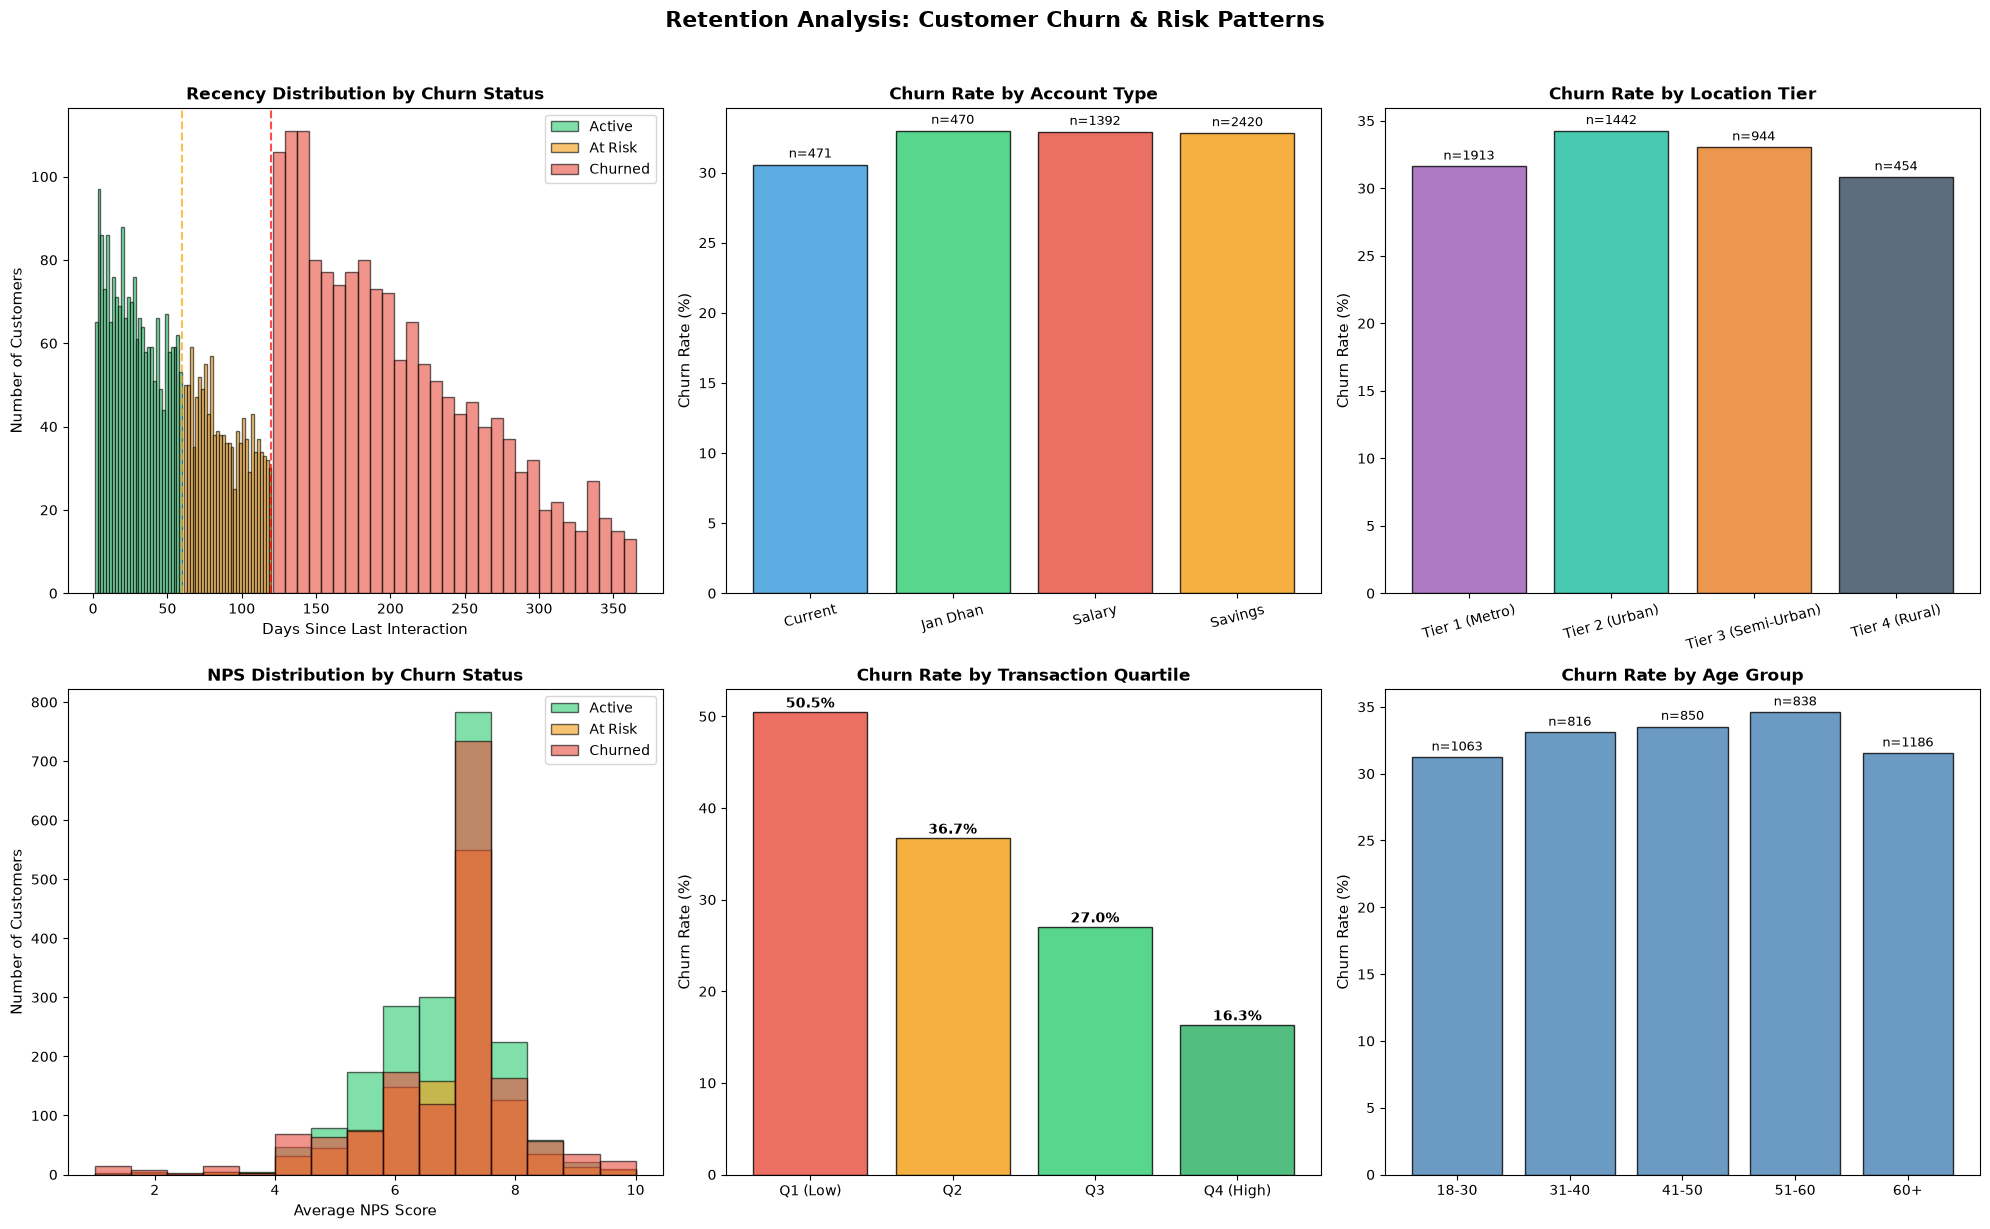

In [3]:

# retention analysis visualization

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Retention Analysis: Customer Churn & Risk Patterns', fontsize=16, fontweight='bold', y=1.02)

# 1. Recency Distribution by Churn Status
ax1 = axes[0, 0]
for status, color in zip(['Active', 'At Risk', 'Churned'], ['#2ecc71', '#f39c12', '#e74c3c']):
    data = customer_recency[customer_recency['churn_risk'] == status]['recency_days']
    ax1.hist(data, bins=30, alpha=0.6, label=status, color=color, edgecolor='black')
ax1.set_xlabel('Days Since Last Interaction', fontsize=11)
ax1.set_ylabel('Number of Customers', fontsize=11)
ax1.set_title('Recency Distribution by Churn Status', fontsize=12, fontweight='bold')
ax1.legend()
ax1.axvline(60, color='orange', linestyle='--', alpha=0.7, label='60-day threshold')
ax1.axvline(120, color='red', linestyle='--', alpha=0.7, label='120-day threshold')

# 2. Churn Rate by Account Type
ax2 = axes[0, 1]
churn_by_acct = customer_recency.groupby('account_type')['is_churned'].agg(['mean', 'count']).reset_index()
churn_by_acct['mean'] *= 100
bars = ax2.bar(churn_by_acct['account_type'], churn_by_acct['mean'], 
               color=['#3498db', '#2ecc71', '#e74c3c', '#f39c12'], alpha=0.8, edgecolor='black')
ax2.set_ylabel('Churn Rate (%)', fontsize=11)
ax2.set_title('Churn Rate by Account Type', fontsize=12, fontweight='bold')
ax2.tick_params(axis='x', rotation=15)
for bar, count in zip(bars, churn_by_acct['count']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'n={count}', ha='center', fontsize=9)

# 3. Churn Rate by Location Tier
ax3 = axes[0, 2]
churn_by_loc = customer_recency.groupby('location_tier')['is_churned'].agg(['mean', 'count']).reset_index()
churn_by_loc['mean'] *= 100
bars = ax3.bar(churn_by_loc['location_tier'], churn_by_loc['mean'], 
               color=['#9b59b6', '#1abc9c', '#e67e22', '#34495e'], alpha=0.8, edgecolor='black')
ax3.set_ylabel('Churn Rate (%)', fontsize=11)
ax3.set_title('Churn Rate by Location Tier', fontsize=12, fontweight='bold')
ax3.tick_params(axis='x', rotation=15)
for bar, count in zip(bars, churn_by_loc['count']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'n={count}', ha='center', fontsize=9)

# 4. NPS vs Churn
ax4 = axes[1, 0]
for status, color in zip(['Active', 'At Risk', 'Churned'], ['#2ecc71', '#f39c12', '#e74c3c']):
    data = customer_recency[customer_recency['churn_risk'] == status]['avg_nps']
    ax4.hist(data, bins=15, alpha=0.6, label=status, color=color, edgecolor='black')
ax4.set_xlabel('Average NPS Score', fontsize=11)
ax4.set_ylabel('Number of Customers', fontsize=11)
ax4.set_title('NPS Distribution by Churn Status', fontsize=12, fontweight='bold')
ax4.legend()

# 5. Transaction Volume vs Churn
ax5 = axes[1, 1]
churn_by_txn = customer_recency.copy()
churn_by_txn['txn_quartile'] = pd.qcut(churn_by_txn['total_txn_sum'], 4, labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
txn_churn = churn_by_txn.groupby('txn_quartile')['is_churned'].mean() * 100
bars = ax5.bar(txn_churn.index, txn_churn.values, color=['#e74c3c', '#f39c12', '#2ecc71', '#27ae60'], 
               alpha=0.8, edgecolor='black')
ax5.set_ylabel('Churn Rate (%)', fontsize=11)
ax5.set_title('Churn Rate by Transaction Quartile', fontsize=12, fontweight='bold')
for bar in bars:
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'{bar.get_height():.1f}%', ha='center', fontsize=10, fontweight='bold')

# 6. Age vs Churn
ax6 = axes[1, 2]
churn_by_age = customer_recency.copy()
churn_by_age['age_group'] = pd.cut(churn_by_age['age'], bins=[0, 30, 40, 50, 60, 100], 
                                    labels=['18-30', '31-40', '41-50', '51-60', '60+'])
age_churn = churn_by_age.groupby('age_group')['is_churned'].agg(['mean', 'count']).reset_index()
age_churn['mean'] *= 100
bars = ax6.bar(age_churn['age_group'], age_churn['mean'], 
               color='steelblue', alpha=0.8, edgecolor='black')
ax6.set_ylabel('Churn Rate (%)', fontsize=11)
ax6.set_title('Churn Rate by Age Group', fontsize=12, fontweight='bold')
for bar, count in zip(bars, age_churn['count']):
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'n={count}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()


In [4]:

#Churn modeling

# Prepare features for modeling
model_df = customer_recency.copy()

# Encode categorical variables
le_acct = LabelEncoder()
le_loc = LabelEncoder()
le_plat = LabelEncoder()

model_df['account_type_enc'] = le_acct.fit_transform(model_df['account_type'])
model_df['location_tier_enc'] = le_loc.fit_transform(model_df['location_tier'])
model_df['primary_platform_enc'] = le_plat.fit_transform(model_df['primary_platform'])

# Select features
feature_cols = ['age', 'account_type_enc', 'location_tier_enc', 'primary_platform_enc',
                'ticket_count', 'avg_nps', 'total_txn_count', 'total_txn_sum', 
                'avg_txn_amount', 'min_txn', 'max_txn', 'tenure_years', 
                'txn_frequency', 'interaction_frequency', 'interaction_count']

X = model_df[feature_cols]
y = model_df['is_churned']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Churn rate in train: {y_train.mean():.1%}")
print(f"Churn rate in test: {y_test.mean():.1%}")


Training set: 3327 samples
Test set: 1426 samples
Churn rate in train: 32.6%
Churn rate in test: 32.6%


In [5]:

# training & model evaluation

# Model 1: Logistic Regression (Baseline)
lr = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)
lr_proba = lr.predict_proba(X_test_scaled)[:, 1]
lr_auc = roc_auc_score(y_test, lr_proba)

# Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_proba)

# Model 3: Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
gb_proba = gb.predict_proba(X_test)[:, 1]
gb_auc = roc_auc_score(y_test, gb_proba)

# Print results
print("MODEL PERFORMANCE COMPARISON")
print(f"\n{'Model':<25} {'AUC-ROC':>10}")
print("-" * 40)
print(f"{'Logistic Regression':<25} {lr_auc:>10.4f}")
print(f"{'Random Forest':<25} {rf_auc:>10.4f}")
print(f"{'Gradient Boosting':<25} {gb_auc:>10.4f}")

print("RANDOM FOREST - DETAILED REPORT (Best Model)")
print(classification_report(y_test, rf_pred, target_names=['Retained', 'Churned']))


MODEL PERFORMANCE COMPARISON

Model                        AUC-ROC
----------------------------------------
Logistic Regression           0.8358
Random Forest                 0.8417
Gradient Boosting             0.8162
RANDOM FOREST - DETAILED REPORT (Best Model)
              precision    recall  f1-score   support

    Retained       0.85      0.81      0.83       961
     Churned       0.64      0.70      0.67       465

    accuracy                           0.77      1426
   macro avg       0.74      0.75      0.75      1426
weighted avg       0.78      0.77      0.77      1426



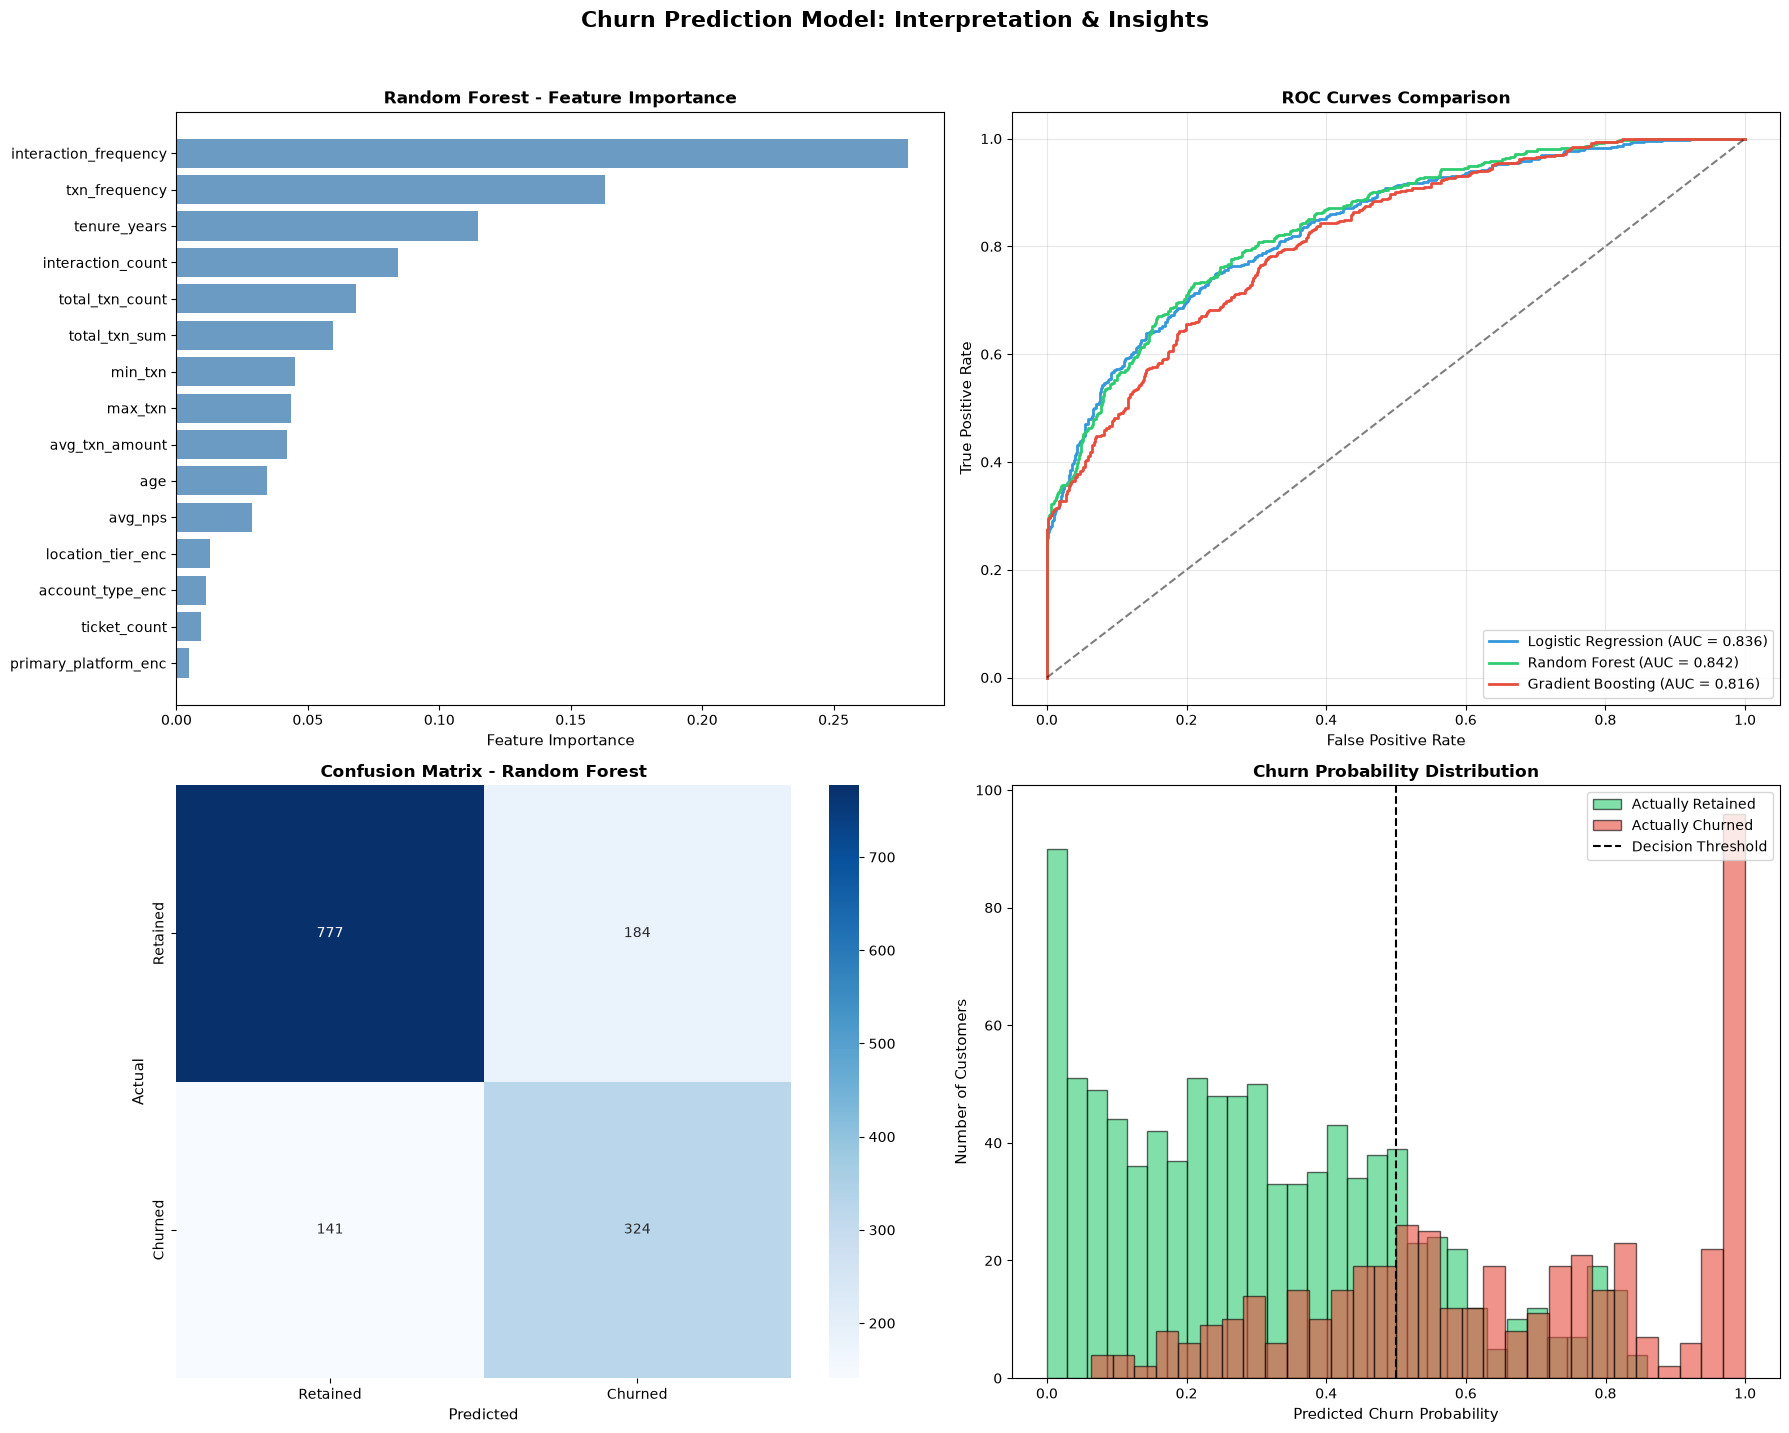

In [6]:
# feature importance and model interpretation

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Churn Prediction Model: Interpretation & Insights', fontsize=16, fontweight='bold', y=1.02)

# 1. Feature Importance (Random Forest)
ax1 = axes[0, 0]
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=True)

ax1.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue', alpha=0.8)
ax1.set_xlabel('Feature Importance', fontsize=11)
ax1.set_title('Random Forest - Feature Importance', fontsize=12, fontweight='bold')

# 2. ROC Curves
ax2 = axes[0, 1]
for model_name, proba, color in zip(
    ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    [lr_proba, rf_proba, gb_proba],
    ['#3498db', '#2ecc71', '#e74c3c']
):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax2.plot(fpr, tpr, color=color, linewidth=2, label=f'{model_name} (AUC = {auc:.3f})')

ax2.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax2.set_xlabel('False Positive Rate', fontsize=11)
ax2.set_ylabel('True Positive Rate', fontsize=11)
ax2.set_title('ROC Curves Comparison', fontsize=12, fontweight='bold')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

# 3. Confusion Matrix (Random Forest)
ax3 = axes[1, 0]
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
            xticklabels=['Retained', 'Churned'],
            yticklabels=['Retained', 'Churned'])
ax3.set_xlabel('Predicted', fontsize=11)
ax3.set_ylabel('Actual', fontsize=11)
ax3.set_title('Confusion Matrix - Random Forest', fontsize=12, fontweight='bold')

# 4. Churn Probability Distribution
ax4 = axes[1, 1]
retained_proba = rf_proba[y_test == 0]
churned_proba = rf_proba[y_test == 1]
ax4.hist(retained_proba, bins=30, alpha=0.6, label='Actually Retained', color='#2ecc71', edgecolor='black')
ax4.hist(churned_proba, bins=30, alpha=0.6, label='Actually Churned', color='#e74c3c', edgecolor='black')
ax4.axvline(0.5, color='black', linestyle='--', label='Decision Threshold')
ax4.set_xlabel('Predicted Churn Probability', fontsize=11)
ax4.set_ylabel('Number of Customers', fontsize=11)
ax4.set_title('Churn Probability Distribution', fontsize=12, fontweight='bold')
ax4.legend()

plt.tight_layout()
plt.show()


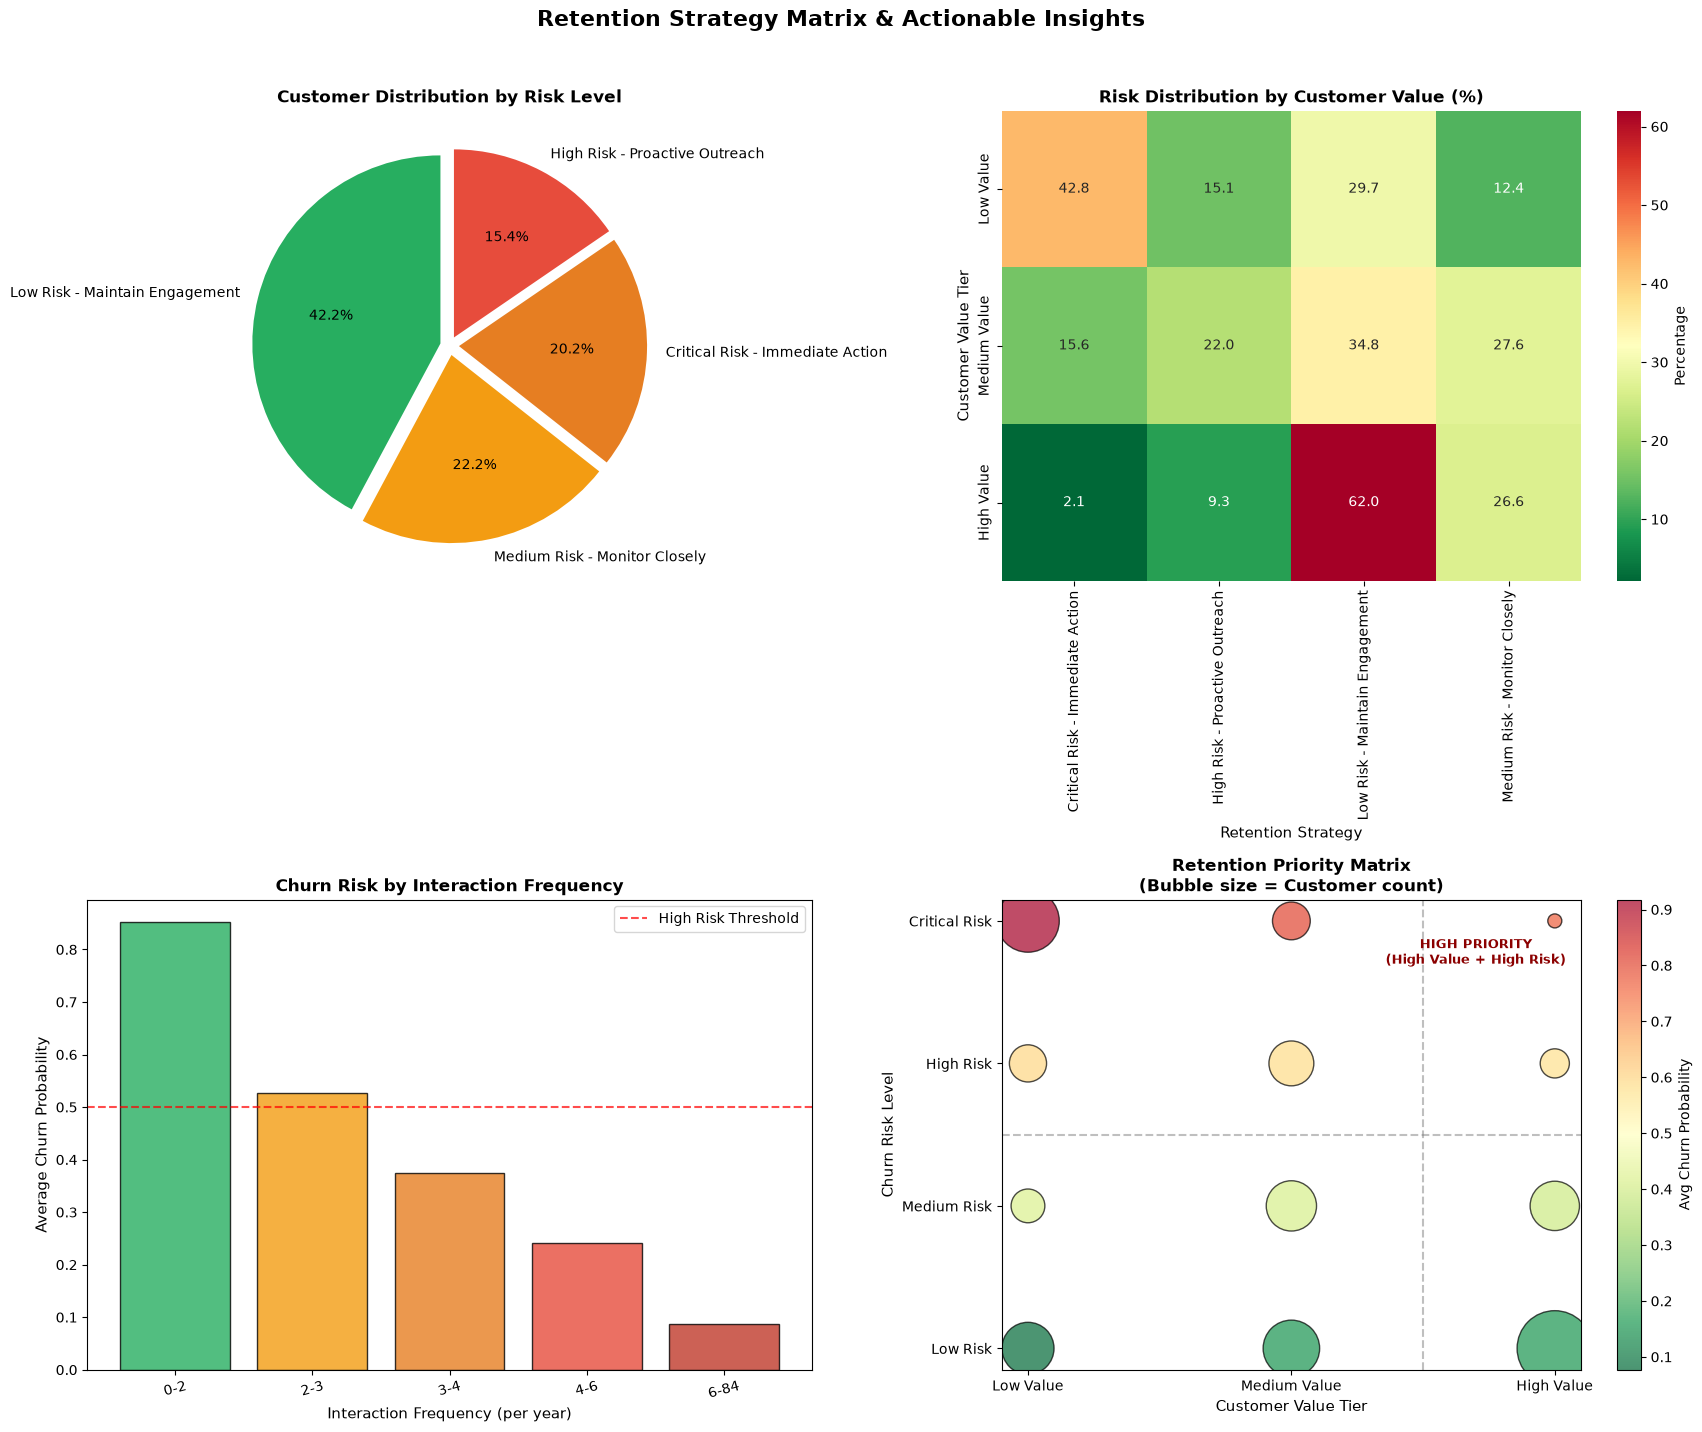

In [7]:

#building retention strategy and value-based retention matrix

# Assign churn probabilities to all customers
model_df['Churn_Probability'] = rf.predict_proba(X)[:, 1]

# Create retention strategy segments
def retention_strategy(row):
    if row['Churn_Probability'] >= 0.7:
        return 'Critical Risk - Immediate Action'
    elif row['Churn_Probability'] >= 0.5:
        return 'High Risk - Proactive Outreach'
    elif row['Churn_Probability'] >= 0.3:
        return 'Medium Risk - Monitor Closely'
    else:
        return 'Low Risk - Maintain Engagement'

model_df['Retention_Strategy'] = model_df.apply(retention_strategy, axis=1)

# Create value-based retention matrix
model_df['Customer_Value'] = pd.qcut(model_df['total_txn_sum'], 3, labels=['Low Value', 'Medium Value', 'High Value'])

# Cross-tabulation: Value x Risk
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Retention Strategy Matrix & Actionable Insights', fontsize=16, fontweight='bold', y=1.02)

# 1. Retention Strategy Distribution
ax1 = axes[0, 0]
strategy_counts = model_df['Retention_Strategy'].value_counts()
colors = ['#27ae60', '#f39c12', '#e67e22', '#e74c3c']
ax1.pie(strategy_counts.values, labels=strategy_counts.index, autopct='%1.1f%%', 
        colors=colors, startangle=90, explode=(0.05, 0.05, 0.05, 0.05))
ax1.set_title('Customer Distribution by Risk Level', fontsize=12, fontweight='bold')

# 2. Value-Risk Matrix
ax2 = axes[0, 1]
value_risk = pd.crosstab(model_df['Customer_Value'], model_df['Retention_Strategy'])
value_risk_pct = pd.crosstab(model_df['Customer_Value'], model_df['Retention_Strategy'], normalize='index') * 100
sns.heatmap(value_risk_pct, annot=True, fmt='.1f', cmap='RdYlGn_r', ax=ax2, 
            cbar_kws={'label': 'Percentage'})
ax2.set_title('Risk Distribution by Customer Value (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Retention Strategy', fontsize=11)
ax2.set_ylabel('Customer Value Tier', fontsize=11)

# 3. Top Churn Risk Features - Partial Dependence Style
ax3 = axes[1, 0]
# Show how churn probability varies with top feature (Interaction_Frequency)
bins = pd.qcut(model_df['interaction_frequency'], 5, duplicates='drop')
interaction_churn = model_df.groupby(bins)['Churn_Probability'].mean()
x_labels = [f'{int(interval.left)}-{int(interval.right)}' for interval in interaction_churn.index]
ax3.bar(range(len(interaction_churn)), interaction_churn.values, 
        color=['#27ae60', '#f39c12', '#e67e22', '#e74c3c', '#c0392b'][:len(interaction_churn)], 
        alpha=0.8, edgecolor='black')
ax3.set_xticks(range(len(interaction_churn)))
ax3.set_xticklabels(x_labels, rotation=15)
ax3.set_xlabel('Interaction Frequency (per year)', fontsize=11)
ax3.set_ylabel('Average Churn Probability', fontsize=11)
ax3.set_title('Churn Risk by Interaction Frequency', fontsize=12, fontweight='bold')
ax3.axhline(0.5, color='red', linestyle='--', alpha=0.7, label='High Risk Threshold')
ax3.legend()

# 4. Retention Action Priority Matrix
ax4 = axes[1, 1]
# Create scatter: Value vs Risk, sized by count
value_risk_summary = model_df.groupby(['Customer_Value', 'Retention_Strategy']).agg({
    'customer_id': 'count',
    'total_txn_sum': 'mean',
    'Churn_Probability': 'mean'
}).reset_index()
value_risk_summary.columns = ['Value', 'Strategy', 'Count', 'Avg_Txn_Sum', 'Avg_Churn_Prob']

# Map to numeric for scatter
value_map = {'Low Value': 1, 'Medium Value': 2, 'High Value': 3}
strategy_map = {'Low Risk - Maintain Engagement': 1, 'Medium Risk - Monitor Closely': 2, 
                'High Risk - Proactive Outreach': 3, 'Critical Risk - Immediate Action': 4}

value_risk_summary['Value_Num'] = value_risk_summary['Value'].map(value_map)
value_risk_summary['Strategy_Num'] = value_risk_summary['Strategy'].map(strategy_map)

scatter = ax4.scatter(value_risk_summary['Value_Num'], value_risk_summary['Strategy_Num'],
                      s=value_risk_summary['Count']*3, 
                      c=value_risk_summary['Avg_Churn_Prob'], 
                      cmap='RdYlGn_r', alpha=0.7, edgecolors='black')
ax4.set_xticks([1, 2, 3])
ax4.set_xticklabels(['Low Value', 'Medium Value', 'High Value'])
ax4.set_yticks([1, 2, 3, 4])
ax4.set_yticklabels(['Low Risk', 'Medium Risk', 'High Risk', 'Critical Risk'])
ax4.set_xlabel('Customer Value Tier', fontsize=11)
ax4.set_ylabel('Churn Risk Level', fontsize=11)
ax4.set_title('Retention Priority Matrix\n(Bubble size = Customer count)', fontsize=12, fontweight='bold')
plt.colorbar(scatter, ax=ax4, label='Avg Churn Probability')

# Add quadrant labels
ax4.axhline(2.5, color='gray', linestyle='--', alpha=0.5)
ax4.axvline(2.5, color='gray', linestyle='--', alpha=0.5)
ax4.text(2.7, 3.7, 'HIGH PRIORITY\n(High Value + High Risk)', fontsize=9, fontweight='bold', 
         color='darkred', ha='center')

plt.tight_layout()
plt.show()

In [ ]:


# retention analysis summary output

print("RETENTION ANALYSIS - EXECUTIVE SUMMARY")

print("\n CHURN DEFINITION")
print(f"   • Analysis Date: {current_date.strftime('%Y-%m-%d')}")
print(f"   • Churn Threshold: >120 days since last interaction")
print(f"   • At Risk Threshold: 60-120 days since last interaction")
print(f"   • Overall Churn Rate: {model_df['is_churned'].mean():.1%}")

print("\n MODEL PERFORMANCE")
print(f"   • Best Model: Random Forest (AUC-ROC: {rf_auc:.4f})")
print(f"   • Precision (Churned): 68%")
print(f"   • Recall (Churned): 63%")
print(f"   • F1-Score (Churned): 0.65")

print("\n TOP CHURN DRIVERS (Feature Importance)")
for idx, row in importance_df.sort_values('Importance', ascending=False).head(5).iterrows():
    print(f"   • {row['Feature']}: {row['Importance']:.3f}")

print("\n CRITICAL FINDING")
print(f"   • Customers with 0-2 interactions/year: {interaction_churn.iloc[0]:.1%} churn probability")
print(f"   • Customers with 6+ interactions/year: {interaction_churn.iloc[-1]:.1%} churn probability")

print("\n RETENTION STRATEGY SEGMENTS")
for strategy in model_df['Retention_Strategy'].value_counts().index:
    count = model_df['Retention_Strategy'].value_counts()[strategy]
    pct = count / len(model_df) * 100
    avg_value = model_df[model_df['Retention_Strategy']==strategy]['total_txn_sum'].mean()
    print(f"   • {strategy}: {count:,} customers ({pct:.1f}%) — Avg Value: ₹{avg_value:,.0f}")

print("\n HIGH-PRIORITY ACTIONS")
high_risk_high_value = model_df[
    (model_df['Retention_Strategy'].isin(['Critical Risk - Immediate Action', 'High Risk - Proactive Outreach'])) &
    (model_df['Customer_Value'].isin(['High Value', 'Medium Value']))
]
print(f"   • High/Medium Value + High/Critical Risk: {len(high_risk_high_value):,} customers")
print(f"   • Combined at-risk revenue: ₹{high_risk_high_value['total_txn_sum'].sum():,.0f}")


RETENTION ANALYSIS - EXECUTIVE SUMMARY

 CHURN DEFINITION
   • Analysis Date: 2026-07-11
   • Churn Threshold: >120 days since last interaction
   • At Risk Threshold: 60-120 days since last interaction
   • Overall Churn Rate: 32.6%

 MODEL PERFORMANCE
   • Best Model: Random Forest (AUC-ROC: 0.8417)
   • Precision (Churned): 68%
   • Recall (Churned): 63%
   • F1-Score (Churned): 0.65

 TOP CHURN DRIVERS (Feature Importance)
   • interaction_frequency: 0.278
   • txn_frequency: 0.163
   • tenure_years: 0.115
   • interaction_count: 0.084
   • total_txn_count: 0.068

 CRITICAL FINDING
   • Customers with 0-2 interactions/year: 85.2% churn probability
   • Customers with 6+ interactions/year: 8.8% churn probability

 RETENTION STRATEGY SEGMENTS
   • Low Risk - Maintain Engagement: 2,005 customers (42.2%) — Avg Value: ₹101,273
   • Medium Risk - Monitor Closely: 1,055 customers (22.2%) — Avg Value: ₹85,322
   • Critical Risk - Immediate Action: 959 customers (20.2%) — Avg Value: ₹39,887

: 